<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_physics/statphys_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Physics* — `statphys_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Statistical Physics — Chapter 3 Figures

Run in Google Colab. All figures saved to `figures/`.

| File | Slide |
|---|---|
| `fig_density_of_states.png` | §3.1 |
| `fig_planck_distribution.png` | §3.2.1 |
| `fig_debye_heat_capacity.png` | §3.3.1 |
| `fig_phonon_dispersion.png` | §3.3 (What's wrong) |
| `fig_bec_condensate_fraction.png` | §3.5.3 |
| `fig_bec_heat_capacity.png` | §3.5.4 |
| `fig_fermi_dirac.png` | §3.6.2 |
| `fig_metal_heat_capacity.png` | §3.6.3 |
| `fig_pauli_susceptibility.png` | §3.6.6 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma as gamma_func
import os

os.makedirs('figures', exist_ok=True)

DARK_BG  = '#1a1a2e'
PANEL_BG = '#16213e'
BLUE     = '#7ec8e3'
YELLOW   = '#f9c74f'
GREEN    = '#90ee90'
RED      = '#e07070'
PURPLE   = '#b39ddb'
ORANGE   = '#ffb347'
DIM      = '#aaaaaa'

def base_style():
    plt.rcParams.update({
        'figure.facecolor': DARK_BG, 'axes.facecolor': PANEL_BG,
        'axes.edgecolor': DIM, 'axes.labelcolor': DIM,
        'axes.titlecolor': BLUE, 'xtick.color': DIM, 'ytick.color': DIM,
        'text.color': DIM, 'grid.color': '#2a2a4e', 'grid.linestyle': '--',
        'grid.alpha': 0.6, 'legend.facecolor': PANEL_BG, 'legend.edgecolor': DIM,
        'legend.labelcolor': DIM, 'font.family': 'sans-serif', 'font.size': 11,
        'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.fontsize': 10,
        'lines.linewidth': 2.0, 'savefig.facecolor': DARK_BG, 'savefig.dpi': 180,
    })

base_style()
print('Ready.')

Ready.


## Fig 1 — Density of States

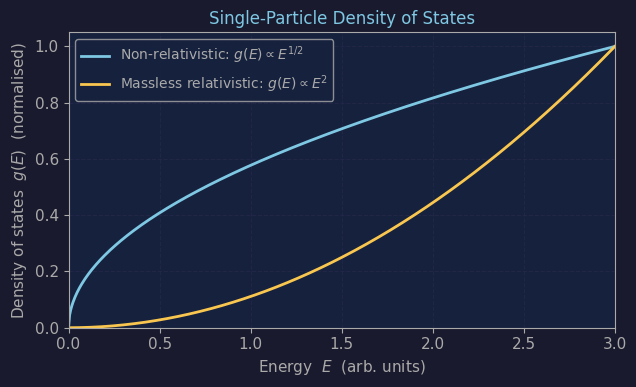

Saved.


In [2]:
base_style()
E = np.linspace(0, 3, 500)

fig, ax = plt.subplots(figsize=(6.5, 4.0))

g_nonrel  = np.sqrt(np.maximum(E, 0))
g_massless = E**2

ax.plot(E, g_nonrel  / g_nonrel.max(),  color=BLUE,   label=r'Non-relativistic: $g(E)\propto E^{1/2}$')
ax.plot(E, g_massless/ g_massless.max(), color=YELLOW, label=r'Massless relativistic: $g(E)\propto E^2$')

ax.set_xlabel('Energy  $E$  (arb. units)')
ax.set_ylabel('Density of states  $g(E)$  (normalised)')
ax.set_title('Single-Particle Density of States')
ax.set_xlim(0, 3)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig('figures/fig_density_of_states.png')
plt.show(); print('Saved.')

## Fig 2 — Planck Distribution

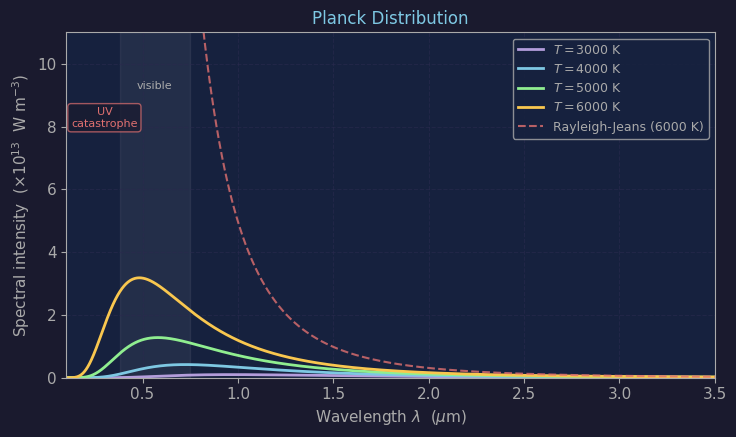

Saved.


In [3]:
base_style()

# Plot in wavelength space (microns) — matches classic textbook figure
lam = np.linspace(0.1, 3.5, 3000)   # microns
hbar = 1.0546e-34; c = 3e8; kB = 1.381e-23
lam_m = lam * 1e-6

temps = [3000, 4000, 5000, 6000]
colors_T = [PURPLE, BLUE, GREEN, YELLOW]

fig, ax = plt.subplots(figsize=(7.5, 4.5))

for T, color in zip(temps, colors_T):
    # Planck in wavelength: B(lambda) = 2hc^2/lambda^5 * 1/(exp(hc/lambda kT)-1)
    x = 2*np.pi*hbar * c / (lam_m * kB * T)
    I = 2 * (2*np.pi*hbar) * c**2 / lam_m**5 / (np.exp(x) - 1)
    ax.plot(lam, I / 1e13, color=color, label=f'$T = {T}$ K', linewidth=2.0)

# Visible spectrum band
ax.axvspan(0.38, 0.75, color='white', alpha=0.06)
ax.text(0.565, 9.2, 'visible', color=DIM, fontsize=8, ha='center')

# Rayleigh-Jeans for 6000 K
T_rj = 6000
I_rj = 2 * c * kB * T_rj / lam_m**4
ax.plot(lam, I_rj / 1e13, color=RED, linestyle='--', linewidth=1.5,
        label='Rayleigh-Jeans (6000 K)', alpha=0.8)

ax.set_xlabel(r'Wavelength $\lambda$  ($\mu$m)')
ax.set_ylabel(r'Spectral intensity  ($\times 10^{13}$  W m$^{-3}$)')
ax.set_title('Planck Distribution')
ax.set_xlim(0.1, 3.5)
ax.set_ylim(0, 11)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True)

ax.annotate('UV\ncatastrophe', xy=(0.3, 8.0), fontsize=8, color=RED, ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor=DARK_BG, edgecolor=RED, alpha=0.7))

fig.tight_layout()
fig.savefig('figures/fig_planck_distribution.png')
plt.show(); print('Saved.')

## Fig 3 — Debye Heat Capacity

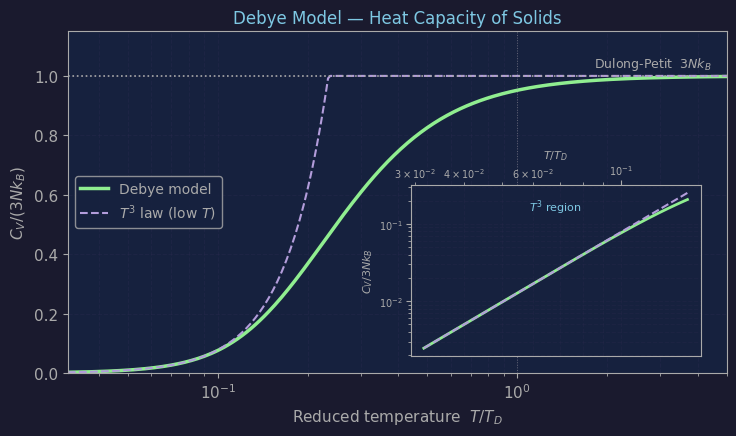

Saved.


In [4]:
base_style()

def debye_CV(T_over_TD):
    """C_V / (3Nk_B) as a function of T/T_D."""
    result = []
    for t in T_over_TD:
        xD = 1.0 / t
        def integrand(x):
            ex = np.exp(x)
            return x**4 * ex / (ex - 1)**2
        val, _ = quad(integrand, 1e-6, xD)
        result.append(3 * t**3 * val)
    return np.array(result)

t_arr    = np.logspace(-1.5, 0.7, 300)
CV_debye = debye_CV(t_arr)

# FIX: T^3 law in same units as debye_CV (= C_V / 3Nk_B)
# low-T limit of Debye integral: int_0^inf = 4pi^4/15
# => C_V/(3Nk_B) = 3*t^3 * (4pi^4/15) = (4pi^4/5) * t^3
CV_T3 = (4 * np.pi**4 / 5) * t_arr**3

fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.plot(t_arr, CV_debye, color=GREEN, linewidth=2.5, label='Debye model')
ax.plot(t_arr, np.minimum(CV_T3, 1.0), color=PURPLE, linestyle='--',
        linewidth=1.5, label=r'$T^3$ law (low $T$)')
ax.axhline(1.0, color=DIM, linestyle=':', linewidth=1.2)
ax.text(1.8, 1.03, 'Dulong-Petit  $3Nk_B$', color=DIM, fontsize=9)
ax.axvline(1.0, color=DIM, linestyle=':', linewidth=0.7, alpha=0.5)

ax.set_xscale('log')
ax.set_xlabel(r'Reduced temperature  $T / T_D$')
ax.set_ylabel(r'$C_V / (3Nk_B)$')
ax.set_title('Debye Model — Heat Capacity of Solids')
ax.set_xlim(t_arr[0], t_arr[-1])
ax.set_ylim(0, 1.15)
ax.legend(loc='center left')
ax.grid(True, which='both', alpha=0.4)

# Inset: T^3 region
axins = ax.inset_axes([0.52, 0.05, 0.44, 0.50])
mask = t_arr < 0.15
axins.plot(t_arr[mask], CV_debye[mask], color=GREEN, linewidth=2.0,
           label='Debye')
axins.plot(t_arr[mask], CV_T3[mask],   color=PURPLE, linestyle='--',
           linewidth=1.5, label=r'$T^3$')
axins.set_xscale('log')
axins.set_yscale('log')
# x tick/label
axins.xaxis.tick_top()
axins.xaxis.set_label_position('top')
axins.set_xlabel(r'$T/T_D$', fontsize=8, labelpad=4)
axins.set_ylabel(r'$C_V/3Nk_B$', fontsize=8, labelpad=3)
axins.tick_params(axis='x', which='both', labelsize=7,
                  top=True, labeltop=True,
                  bottom=False, labelbottom=False, pad=2)
axins.tick_params(axis='y', which='both', labelsize=7, pad=2)
axins.set_facecolor(PANEL_BG)
axins.grid(True, which='both', alpha=0.3)
axins.text(0.5, 0.93, r'$T^3$ region',
           transform=axins.transAxes,
           fontsize=8, color=BLUE, ha='center', va='top')

fig.tight_layout()
fig.savefig('figures/fig_debye_heat_capacity.png')
plt.show(); print('Saved.')


## Fig 4 — Phonon Dispersion Relation

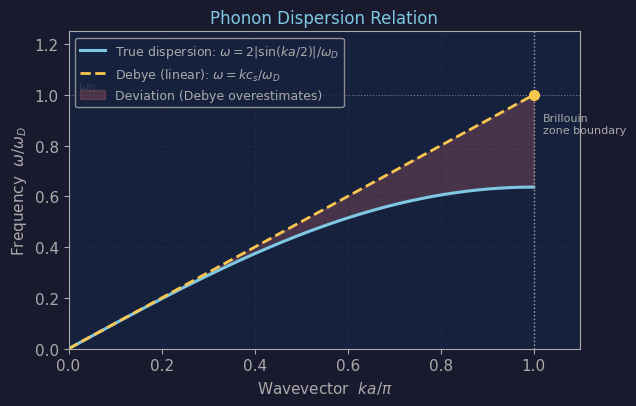

Saved.


In [5]:
base_style()

k = np.linspace(0, np.pi, 500)   # ka in [0, pi]

# 1D chain dispersion, cs = 1  =>  omega_D = cs * k_D = pi
omega_D = np.pi
omega_true  = 2 * np.abs(np.sin(k / 2)) / omega_D   # normalised to omega_D
omega_debye = k / omega_D                            # linear: omega = cs*k

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.plot(k / np.pi, omega_true,
        color=BLUE,   linewidth=2.2,
        label=r'True dispersion: $\omega = 2|\sin(ka/2)|/\omega_D$')
ax.plot(k / np.pi, omega_debye,
        color=YELLOW, linewidth=2.0, linestyle='--',
        label=r'Debye (linear): $\omega = kc_s/\omega_D$')

# BZ boundary
ax.axvline(1.0, color=DIM, linestyle=':', linewidth=1.0)
ax.text(1.02, 0.85, 'Brillouin\nzone boundary', color=DIM, fontsize=8)

# Debye 선이 BZ boundary (ka/pi=1)에서 omega/omega_D=1 에 도달함을 표시
ax.plot(1.0, 1.0, 'o', color=YELLOW, markersize=7, zorder=5)
ax.axhline(1.0, color=DIM, linestyle=':', linewidth=0.8, alpha=0.6)
ax.text(0.02, 1.02, r'$\omega_D$', color=DIM, fontsize=9)

# FIX: fill_between — deviation region (alpha 키우고, 전체 구간)
ax.fill_between(k / np.pi, omega_true, omega_debye,
                where=(omega_debye > omega_true),
                alpha=0.25, color=RED, label='Deviation (Debye overestimates)')

ax.set_xlabel(r'Wavevector  $ka/\pi$')
ax.set_ylabel(r'Frequency  $\omega/\omega_D$')
ax.set_title('Phonon Dispersion Relation')
ax.set_xlim(0, 1.1)
ax.set_ylim(0, 1.25)
ax.legend(loc='upper left', fontsize=9)
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_phonon_dispersion.png')
plt.show(); print('Saved.')


## Fig 5 — BEC Condensate Fraction

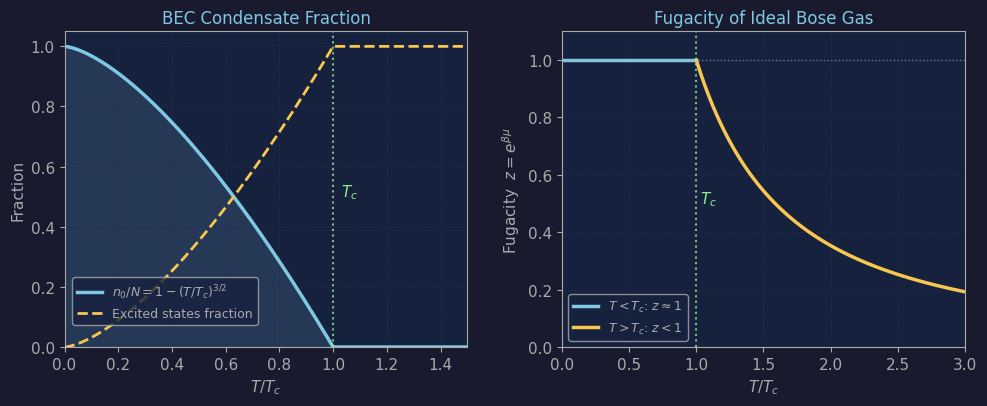

Saved.


In [6]:
base_style()

t = np.linspace(0, 1.5, 500)   # T/Tc

# Condensate fraction n0/N = 1 - (T/Tc)^(3/2) for T < Tc
n0_frac = np.where(t <= 1, 1 - t**1.5, 0)
excited_frac = 1 - n0_frac

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Left: condensate fraction
ax = axes[0]
ax.plot(t, n0_frac, color=BLUE, linewidth=2.5, label=r'$n_0/N = 1-(T/T_c)^{3/2}$')
ax.plot(t, excited_frac, color=YELLOW, linewidth=2.0, linestyle='--',
        label='Excited states fraction')
ax.axvline(1.0, color=GREEN, linestyle=':', linewidth=1.5, alpha=0.8)
ax.text(1.03, 0.5, r'$T_c$', color=GREEN, fontsize=11)
ax.fill_between(t[t<=1], n0_frac[t<=1], alpha=0.15, color=BLUE)
ax.set_xlabel(r'$T / T_c$')
ax.set_ylabel(r'Fraction')
ax.set_title('BEC Condensate Fraction')
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.05)
ax.legend(fontsize=9, bbox_to_anchor=(0.495, 0.05)); ax.grid(True)

# Right: fugacity z vs T/Tc
ax = axes[1]
# Above Tc: z determined by N/V = g_{3/2}(z)/lambda^3
# For illustration, use approximate z ≈ (T/Tc)^{3/2} * zeta(3/2) / g_{3/2}(z)
# Simple: z ~= (T_c/T)^(3/2) at high T (z -> 0)
# At T=Tc: z->1; Below Tc: z~1-1/N
t_above = np.linspace(1.0, 3.0, 200)
# Approximate: z ≈ exp(mu/kT) with mu ≈ -kT*ln(V/N*lambda^3) classical
# Simpler schematic: z = (T_c/T)^(3/2) (leading order)
z_above = (1.0 / t_above)**1.5  # schematic
t_below = np.linspace(0, 1.0, 200)
z_below = np.ones_like(t_below) * (1 - 1e-4)  # z≈1 for T<Tc

ax.plot(t_below, z_below, color=BLUE, linewidth=2.5, label=r'$T < T_c$: $z \approx 1$')
ax.plot(t_above, z_above, color=YELLOW, linewidth=2.5, label=r'$T > T_c$: $z < 1$')
ax.axvline(1.0, color=GREEN, linestyle=':', linewidth=1.5, alpha=0.8)
ax.text(1.03, 0.5, r'$T_c$', color=GREEN, fontsize=11)
ax.axhline(1.0, color=DIM, linestyle=':', linewidth=1.0, alpha=0.6)
ax.set_xlabel(r'$T / T_c$')
ax.set_ylabel(r'Fugacity  $z = e^{\beta\mu}$')
ax.set_title('Fugacity of Ideal Bose Gas')
ax.set_xlim(0, 3); ax.set_ylim(0, 1.1)
ax.legend(fontsize=9); ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_bec_condensate_fraction.png')
plt.show(); print('Saved.')

## Fig 6 — BEC Heat Capacity

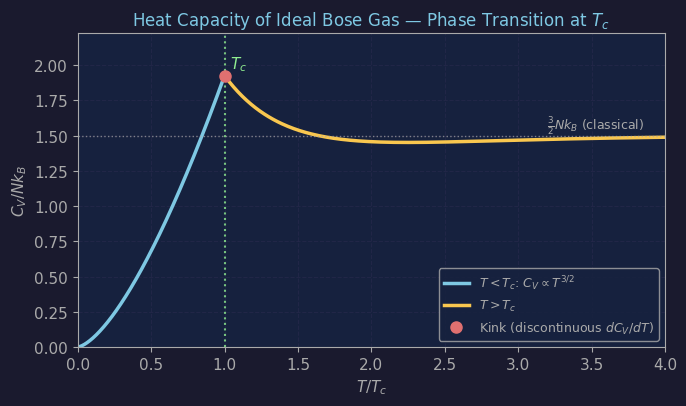

Saved.


In [7]:
base_style()

# Zeta values
zeta_3_2 = 2.6124  # zeta(3/2)
zeta_5_2 = 1.3415  # zeta(5/2)

# Below Tc: CV/Nk_B = (15/4) * zeta(5/2)/zeta(3/2) * (T/Tc)^(3/2)
coeff_below = 15/4 * zeta_5_2 / zeta_3_2

t_below = np.linspace(0, 1.0, 300)
CV_below = coeff_below * t_below**1.5

# Above Tc: schematic — starts from peak at Tc, decreases and approaches 3/2 at high T
t_above = np.linspace(1.0, 4.0, 300)
CV_peak = coeff_below  # value at Tc from below
# Smooth interpolation from peak to classical 3/2
CV_above = 1.5 + (CV_peak - 1.5) * np.exp(-2.5*(t_above - 1.0))
# Add linear correction (from the dz/dT term)
CV_above = CV_above - 0.35 * (t_above - 1.0) * np.exp(-1.5*(t_above-1.0))

fig, ax = plt.subplots(figsize=(7, 4.2))

ax.plot(t_below, CV_below, color=BLUE, linewidth=2.5, label=r'$T < T_c$: $C_V \propto T^{3/2}$')
ax.plot(t_above, CV_above, color=YELLOW, linewidth=2.5, label=r'$T > T_c$')
ax.axvline(1.0, color=GREEN, linestyle=':', linewidth=1.5, alpha=0.8)
ax.axhline(1.5, color=DIM, linestyle=':', linewidth=1.0, alpha=0.7)
ax.text(3.2, 1.55, r'$\frac{3}{2}Nk_B$ (classical)', color=DIM, fontsize=9)
ax.text(1.04, CV_peak + 0.05, r'$T_c$', color=GREEN, fontsize=11)

# Mark the kink
ax.plot(1.0, CV_peak, 'o', color=RED, markersize=8, zorder=5, label='Kink (discontinuous $dC_V/dT$)')

ax.set_xlabel(r'$T / T_c$')
ax.set_ylabel(r'$C_V / Nk_B$')
ax.set_title('Heat Capacity of Ideal Bose Gas — Phase Transition at $T_c$')
ax.set_xlim(0, 4); ax.set_ylim(0, CV_peak + 0.3)
ax.legend(loc='lower right', fontsize=9); ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_bec_heat_capacity.png')
plt.show(); print('Saved.')

## Fig 7 — Fermi-Dirac Distribution

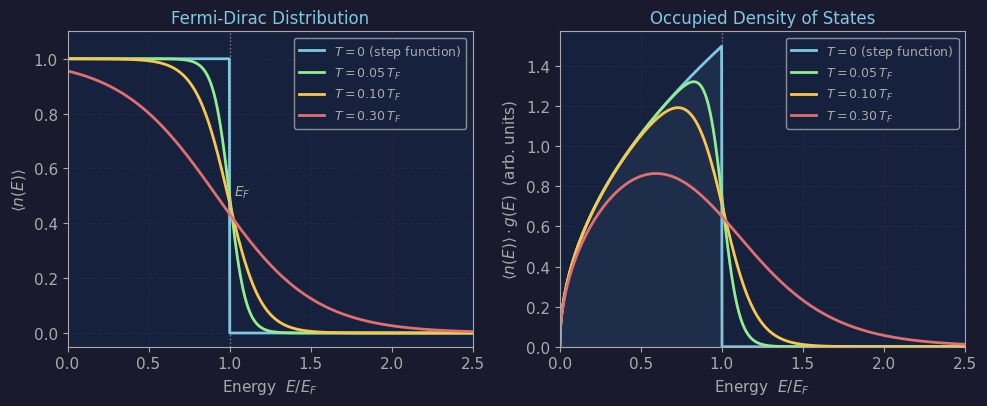

Saved.


In [8]:
base_style()

E = np.linspace(0, 2.5, 1000)  # in units of E_F
EF = 1.0

def fermi_dirac(E, mu, T_over_TF):
    if T_over_TF == 0:
        return np.where(E <= mu, 1.0, 0.0)
    beta_EF = 1.0 / T_over_TF
    x = beta_EF * (E - mu)
    return 1.0 / (np.exp(np.clip(x, -500, 500)) + 1)

cases = [
    (0.0,  1.0,  BLUE,   r'$T = 0$ (step function)'),
    (0.05, 1.0,  GREEN,  r'$T = 0.05\,T_F$'),
    (0.1,  0.99, YELLOW, r'$T = 0.10\,T_F$'),
    (0.3,  0.92, RED,    r'$T = 0.30\,T_F$'),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Left: Fermi-Dirac distribution
ax = axes[0]
for T_over_TF, mu, color, label in cases:
    n = fermi_dirac(E, mu, T_over_TF)
    ax.plot(E, n, color=color, linewidth=2.0, label=label)
ax.axvline(EF, color=DIM, linestyle=':', linewidth=1.0, alpha=0.7)
ax.text(1.03, 0.5, r'$E_F$', color=DIM, fontsize=10)
ax.set_xlabel(r'Energy  $E / E_F$')
ax.set_ylabel(r'$\langle n(E)\rangle$')
ax.set_title('Fermi-Dirac Distribution')
ax.set_xlim(0, 2.5); ax.set_ylim(-0.05, 1.1)
ax.legend(fontsize=9); ax.grid(True)

# Right: occupation * density of states  n(E)*g(E)
ax = axes[1]
g = np.sqrt(E)   # proportional to density of states
for T_over_TF, mu, color, label in cases:
    n = fermi_dirac(E, mu, T_over_TF)
    ax.plot(E, n * g / (2/3), color=color, linewidth=2.0, label=label)
ax.axvline(EF, color=DIM, linestyle=':', linewidth=1.0, alpha=0.7)
ax.fill_between(E, 0, fermi_dirac(E, 1.0, 0) * g / (2/3), alpha=0.08, color=BLUE)
ax.set_xlabel(r'Energy  $E / E_F$')
ax.set_ylabel(r'$\langle n(E)\rangle \cdot g(E)$  (arb. units)')
ax.set_title('Occupied Density of States')
ax.set_xlim(0, 2.5); ax.set_ylim(0)
ax.legend(fontsize=9); ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_fermi_dirac.png')
plt.show(); print('Saved.')

## Fig 8 — Metal Heat Capacity (electron + phonon)

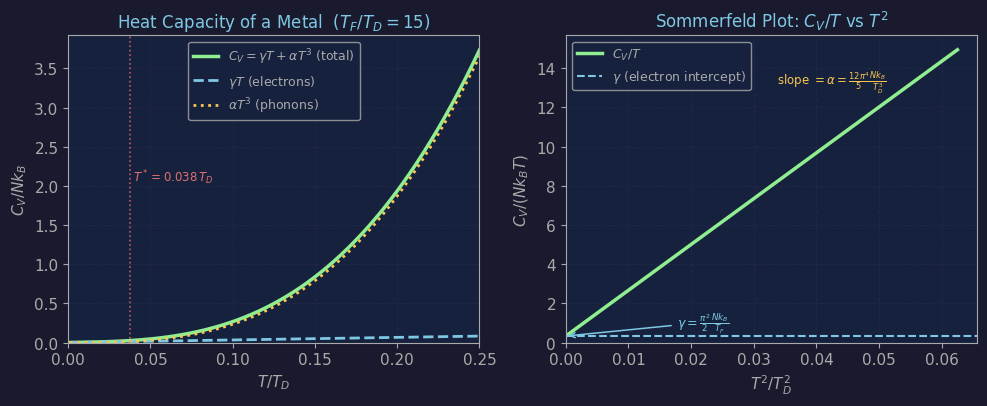

Saved.


In [9]:
base_style()

# C_V = gamma*T + alpha*T^3,  T in units of T_D
# gamma = (pi^2/2) * Nk_B/T_F,  alpha = (12pi^4/5) * Nk_B/T_D^3
# FIX: TF/TD = 15 (교육용 — 전자/포논 기여가 모두 보이게)
T_F_ratio = 15.0   # T_F / T_D

gamma = np.pi**2 / 2 / T_F_ratio
alpha = 12 * np.pi**4 / 5

T = np.linspace(0.001, 0.25, 300)

CV_elec  = gamma * T
CV_phon  = alpha * T**3
CV_total = CV_elec + CV_phon

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# ── Left: C_V vs T ────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(T, CV_total, color=GREEN,  linewidth=2.5,
        label=r'$C_V = \gamma T + \alpha T^3$ (total)')
ax.plot(T, CV_elec,  color=BLUE,   linewidth=2.0, linestyle='--',
        label=r'$\gamma T$ (electrons)')
ax.plot(T, CV_phon,  color=YELLOW, linewidth=2.0, linestyle=':',
        label=r'$\alpha T^3$ (phonons)')

# Crossover temperature: gamma*T = alpha*T^3  =>  T* = sqrt(gamma/alpha)
T_cross = np.sqrt(gamma / alpha)
ax.axvline(T_cross, color=RED, linestyle=':', linewidth=1.2, alpha=0.8)
ax.text(T_cross * 1.05, CV_total.max() * 0.55,
        r'$T^* = $' + f'{T_cross:.3f}' + r'$\,T_D$',
        color=RED, fontsize=8.5)

ax.set_xlabel(r'$T / T_D$')
ax.set_ylabel(r'$C_V / Nk_B$')
ax.set_title(r'Heat Capacity of a Metal  ($T_F/T_D = 15$)')
ax.set_xlim(0, 0.25)
ax.set_ylim(0)
ax.legend(fontsize=9)
ax.grid(True)

# ── Right: C_V/T vs T^2  (Sommerfeld plot) ───────────────────────────────
ax = axes[1]
T2        = T**2
CV_over_T = CV_total / T   # = gamma + alpha*T^2  (linear in T^2)

ax.plot(T2, CV_over_T, color=GREEN, linewidth=2.5, label=r'$C_V/T$')

# gamma intercept (T^2 -> 0)
ax.axhline(gamma, color=BLUE, linestyle='--', linewidth=1.5,
           label=r'$\gamma$ (electron intercept)')

# annotate intercept clearly with arrow
ax.annotate(r'$\gamma = \frac{\pi^2}{2}\frac{Nk_B}{T_F}$',
            xy=(0.0, gamma), xytext=(T2.max()*0.35, gamma * 2.5),
            color=BLUE, fontsize=9, ha='center',
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.1))

# slope annotation
ax.text(T2.max()*0.60 +0.005, CV_over_T[-1]*0.88,
        r'slope $= \alpha = \frac{12\pi^4}{5}\frac{Nk_B}{T_D^3}$',
        color=YELLOW, fontsize=8.5, ha='center')

ax.set_xlabel(r'$T^2 / T_D^2$')
ax.set_ylabel(r'$C_V / (Nk_BT)$')
ax.set_title(r'Sommerfeld Plot: $C_V/T$ vs $T^2$')
ax.set_xlim(0)
ax.set_ylim(0)
ax.legend(fontsize=9, loc='upper left')
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_metal_heat_capacity.png')
plt.show(); print('Saved.')


## Fig 9 — Pauli Paramagnetism (χ vs T)

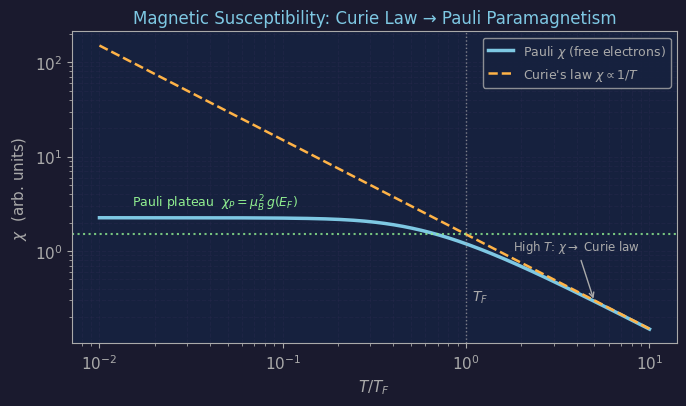

Saved.


In [10]:
base_style()

from scipy.optimize import brentq
import warnings

# T in units of T_F (E_F = k_B T_F = 1)
T = np.logspace(-2, 1, 300)

def find_mu(T_val):
    """Chemical potential that conserves particle number at temperature T.
    Normalised so that int_0^inf g(e)*f(e) de = 1,  g(e) = (3/2)*sqrt(e).
    """
    def n_eq(mu):
        def intgd(e):
            xc = np.clip((e - mu) / T_val, -500, 500)
            return (3/2) * np.sqrt(e) / (np.exp(xc) + 1)
        v, _ = quad(intgd, 0, max(mu + 50*T_val, 10), limit=200)
        return v - 1.0
    return brentq(n_eq, -200*T_val, 2.0, xtol=1e-10)

def chi_T(T_val):
    """chi(T) / (N mu_B^2 / E_F)  via correct mu and -df/dE integral."""
    mu = find_mu(T_val)
    def intgd(e):
        if e < 0: return 0.0
        xc = np.clip((e - mu) / T_val, -500, 500)
        ex = np.exp(xc)
        return (3/2) * np.sqrt(e) * ex / ((ex + 1)**2 * T_val)
    lo = max(0.0, mu - 30*T_val)
    hi = max(mu + 30*T_val, 5.0)
    v, _ = quad(intgd, lo, hi, limit=300)
    return v

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    chi_ratio = np.array([chi_T(t) for t in T])

# chi_P = (3/2): Pauli zero-T limit in units of N*mu_B^2/E_F
chi_P     = 1.5
chi_total = chi_P * chi_ratio
chi_curie = chi_P / T    # Curie law: same prefactor by construction

fig, ax = plt.subplots(figsize=(7, 4.2))

ax.loglog(T, chi_total, color=BLUE, linewidth=2.5,
          label=r'Pauli $\chi$ (free electrons)')
ax.loglog(T, chi_curie, color=ORANGE, linewidth=1.8, linestyle='--',
          label=r"Curie's law $\chi \propto 1/T$")

# Low-T plateau
ax.axhline(chi_P, color=GREEN, linewidth=1.5, linestyle=':', alpha=0.8)
ax.text(1.5e-2, chi_P * 1.3 +1.0,
        r'Pauli plateau  $\chi_P = \mu_B^2\, g(E_F)$',
        color=GREEN, fontsize=9)

# T_F marker
ax.axvline(1.0, color=DIM, linestyle=':', linewidth=1.0, alpha=0.7)
ax.text(1.08, chi_total.min() * 2.0, r'$T_F$', color=DIM, fontsize=10)

# Convergence annotation at high T
idx = np.argmin(np.abs(T - 5.0))
ax.annotate(r'High $T$: $\chi \to$ Curie law',
            xy=(T[idx], chi_total[idx]),
            xytext=(1.5 +2.5, chi_total[idx] * 3.5),
            color=DIM, fontsize=8.5, ha='center',
            arrowprops=dict(arrowstyle='->', color=DIM, lw=1.0))

ax.set_xlabel(r'$T / T_F$')
ax.set_ylabel(r'$\chi$  (arb. units)')
ax.set_title('Magnetic Susceptibility: Curie Law → Pauli Paramagnetism')
ax.legend(fontsize=9)
ax.grid(True, which='both', alpha=0.4)

fig.tight_layout()
fig.savefig('figures/fig_pauli_susceptibility.png')
plt.show(); print('Saved.')


## Summary

All figures saved to `./figures/`.

Copy the `figures/` folder next to `statphys_ch03_slides.qmd` and render:
```bash
quarto render statphys_ch03_slides.qmd
```

In [11]:
# ── Download all figures as a zip file (Colab) ──────────────────────────────
import zipfile
import os

zip_path = 'statphys_ch03_figures.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)  # store without 'figures/' prefix
            print(f'  Added: {fname}')

print(f'\nZip created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path) / 1024:.1f} KB')

# Download in Google Colab
try:
    from google.colab import files
    files.download(zip_path)
    print('Download started!')
except ImportError:
    print(f'Not running in Colab — file saved locally as: {zip_path}')


  Added: fig_bec_condensate_fraction.png
  Added: fig_bec_heat_capacity.png
  Added: fig_debye_heat_capacity.png
  Added: fig_density_of_states.png
  Added: fig_fermi_dirac.png
  Added: fig_metal_heat_capacity.png
  Added: fig_pauli_susceptibility.png
  Added: fig_phonon_dispersion.png
  Added: fig_planck_distribution.png

Zip created: statphys_ch03_figures.zip
Size: 892.6 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
